# Week 13 extension: regional accuracy in a D/W=5 cavity

**Authors' research evidence:** Ehsan Roohi and Christopher J. McDevitt,
[Regional accuracy of PINNs for recirculation in a deep lid-driven cavity](https://arxiv.org/abs/2610.38814v2).
This separate CPU notebook complements the existing Week 13 square/D=2/D=2.2
notebook. It loads retained CFD/PINN fields, recomputes errors, and studies weak
recirculation, pressure and derivatives. It does not retrain the paper's networks.

**Geometric depth D/W=5 is not five network layers.** The four cases are Re=100,
250,500,1000; their Gaussian-regularized lid is not Ghia's square-cavity lid.
Width W, lid scale U, density rho, and height h measured from the floor set the
units. Arrays have shape [h,x], 605 by 121, and exclude the exact walls by 0.002 W.

[Lecture](../../lectures/week13_rectangular_cavity_pinn.pdf) Â·
[Data and provenance](../../data/week13_d5/README.md) Â·
[Results](../../results/week13_d5/README.md) Â· [Setup](../../START_HERE.md).
Prerequisites: Week 1 validation, Week 1.3 optimization, Week 13 PINN basics.
The CPU route needs NumPy, pandas and Matplotlib; no GPU or TensorFlow is required.

[Open in Colab](https://colab.research.google.com/github/Ehsan-Roohi/FlowMLLab/blob/main/notebooks/week13/W13_Deep_Cavity_D5_Regional_Accuracy.ipynb)

In [1]:
from pathlib import Path
import sys, subprocess
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents, Path('/content/FlowMLLab')]
             if (p/'flowmllab/ghia.py').is_file()), None)
if ROOT is None:
    candidate = Path('/content/FlowMLLab') if Path('/content').is_dir() else Path.cwd()/'FlowMLLab'
    if not candidate.exists():
        subprocess.run(['git','clone','--depth','1','https://github.com/Ehsan-Roohi/FlowMLLab.git',str(candidate)],check=True)
    if not (candidate/'flowmllab/ghia.py').is_file():
        raise RuntimeError('This checkout predates the cavity extension. Use an updated FlowMLLab checkout after saving your student work; do not overwrite your edited notebook.')
    ROOT = candidate
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown
from flowmllab import ghia, cavity_course as course

## 1. Verify the field identity before comparing

The loader checks the compressed bundle hash. The original arrays have been
retained exactly; only redundant speed arrays were omitted. The common-grid
Re=1000 field is the **control** trajectory. It is not the refined result from
the separate 161 by 801 assessment. CFD times are 120,160,160,317 respectively;
these are reference-solver times, not neural optimizer iterations.

In [2]:
from flowmllab.deep_cavity_audit import load_bundle, evaluate, masks, metrics, horizontal_profile
fields, provenance = load_bundle(ROOT/'data/week13_d5')
print('Geometry:',provenance['aspect_ratio_D_W'],'| shape [h,x]:',provenance['grid_shape_h_x'])
print('CFD times:',provenance['CFD_times'])
print('Pressure convention:',provenance['pressure'])
print('Bundle SHA256:',provenance['data_sha256'])
table=pd.DataFrame(evaluate(fields))
display(table[['Re','region','count','velocity_RMS_U','CFD_velocity_RMS_U',
               'velocity_NRMSE_percent','pressure_RMS_rhoU2','vorticity_NRMSE_percent']])

Geometry: 5 | shape [h,x]: [605, 121]
CFD times: {'100': 120, '250': 160, '500': 160, '1000': 317.00000000827623}
Pressure convention: frozen common whole-interior gauge, preserved without recentering
Bundle SHA256: e491c85e542f0414e7527f00bd01440813588d0aa63d625f74a27ee8f997ada7


,Re,region,count,velocity_RMS_U,CFD_velocity_RMS_U,velocity_NRMSE_percent,pressure_RMS_rhoU2,vorticity_NRMSE_percent
0,100,Interior,68885,8.048943e-03,1.058360e-01,7.605110,0.005838,42.774526
1,100,Upper-left,729,7.123244e-02,2.521590e-01,28.249016,0.053871,83.999092
2,100,Floor_0.4,5290,6.243409e-11,5.347636e-09,1.167508,0.000103,1.181121
3,100,Floor_0.65,8740,1.255095e-10,9.051358e-09,1.386638,0.000103,1.109036
4,250,Interior,68885,7.673662e-03,1.143428e-01,6.711104,0.002498,41.103514
5,250,Upper-left,729,6.702416e-02,2.078168e-01,32.251565,0.020738,95.728314
6,250,Floor_0.4,5290,4.135197e-10,1.384216e-08,2.987394,0.000244,2.974057
7,250,Floor_0.65,8740,9.133129e-10,3.079395e-08,2.965884,0.000244,2.972093
8,500,Interior,68885,9.541108e-03,1.215447e-01,7.849874,0.002082,44.875798
9,500,Upper-left,729,7.748204e-02,1.981329e-01,39.106100,0.013444,128.010307


## 2. The physics and the error definitions

A streamfunction imposes $u=\partial\psi/\partial h$ and
$v=-\partial\psi/\partial x$, so continuity is satisfied analytically.
Momentum residuals and wall conditions still need to be satisfied; differentiating
velocity to obtain $\omega=\partial v/\partial x-\partial u/\partial h$
can amplify a small field error. The supplied vorticity is sampled finite
differences on the common grid, not a comparison of native AD/spectral derivatives.

For a fixed region R with N equally weighted retained nodes:
$$e_{u,R}=\sqrt{N^{-1}\sum_{i\in R}[(\hat u_i-u_i)^2+(\hat v_i-v_i)^2]},\quad
E_{u,R}=100\,\frac{e_{u,R}}{\sqrt{N^{-1}\sum_{i\in R}(u_i^2+v_i^2)}}.$$
All velocities in the file are normalized by U. A tiny absolute floor error
can coexist with a measurable relative error because the reference flow is tiny.
Neither quantity is a statistical uncertainty estimate or a numerical noise floor.

Pressure is fixed to one whole-interior gauge before regional comparisons.
Let $\delta p_i=\hat p_i-p_i$, $b_R=\langle\delta p\rangle_R$ and
$s_R=\sqrt{\langle(\delta p-b_R)^2\rangle_R}$. Then
$$e_{p,R}^2=b_R^2+s_R^2.$$
Report RMS, signed offset and local shape together. Re-centering each region
silently would remove the offset and change the stated metric.

In [3]:
identity = table.pressure_RMS_rhoU2**2 - (
    table.pressure_signed_mean_offset_rhoU2**2 + table.pressure_local_shape_RMS_rhoU2**2)
print('Largest pressure decomposition residual:', abs(identity).max())
display(table[['Re','region','pressure_RMS_rhoU2','pressure_signed_mean_offset_rhoU2',
               'pressure_local_shape_RMS_rhoU2']])

Largest pressure decomposition residual: 8.673617379884035e-19


,Re,region,pressure_RMS_rhoU2,pressure_signed_mean_offset_rhoU2,pressure_local_shape_RMS_rhoU2
0,100,Interior,0.005838,1.066826e-10,5.838296e-03
1,100,Upper-left,0.053871,-7.921893e-04,5.386473e-02
2,100,Floor_0.4,0.000103,1.033302e-04,9.619831e-11
3,100,Floor_0.65,0.000103,1.033302e-04,1.151727e-10
4,250,Interior,0.002498,2.449792e-17,2.498072e-03
5,250,Upper-left,0.020738,-2.169707e-04,2.073677e-02
6,250,Floor_0.4,0.000244,2.443874e-04,2.399771e-12
7,250,Floor_0.65,0.000244,2.443874e-04,8.709137e-12
8,500,Interior,0.002082,6.395246e-17,2.082376e-03
9,500,Upper-left,0.013444,4.687568e-04,1.343580e-02


## 3. Inspect every retained Reynolds number

For each Re, CFD and PINN speed have the **same** full-range symmetric-log color
scale so weak lower vortices remain visible. The signed u discrepancy uses a
separate linear scale. Profiles compare u, globally gauged p and sampled vorticity
at three actual retained heights; no curve outside the retained mesh is invented.
Do not infer a smaller error from a different color transform.

Re = 100: matched geometry/lid, common sampled grid
Re = 250: matched geometry/lid, common sampled grid
Re = 500: matched geometry/lid, common sampled grid
Re = 1000: matched geometry/lid, common sampled grid


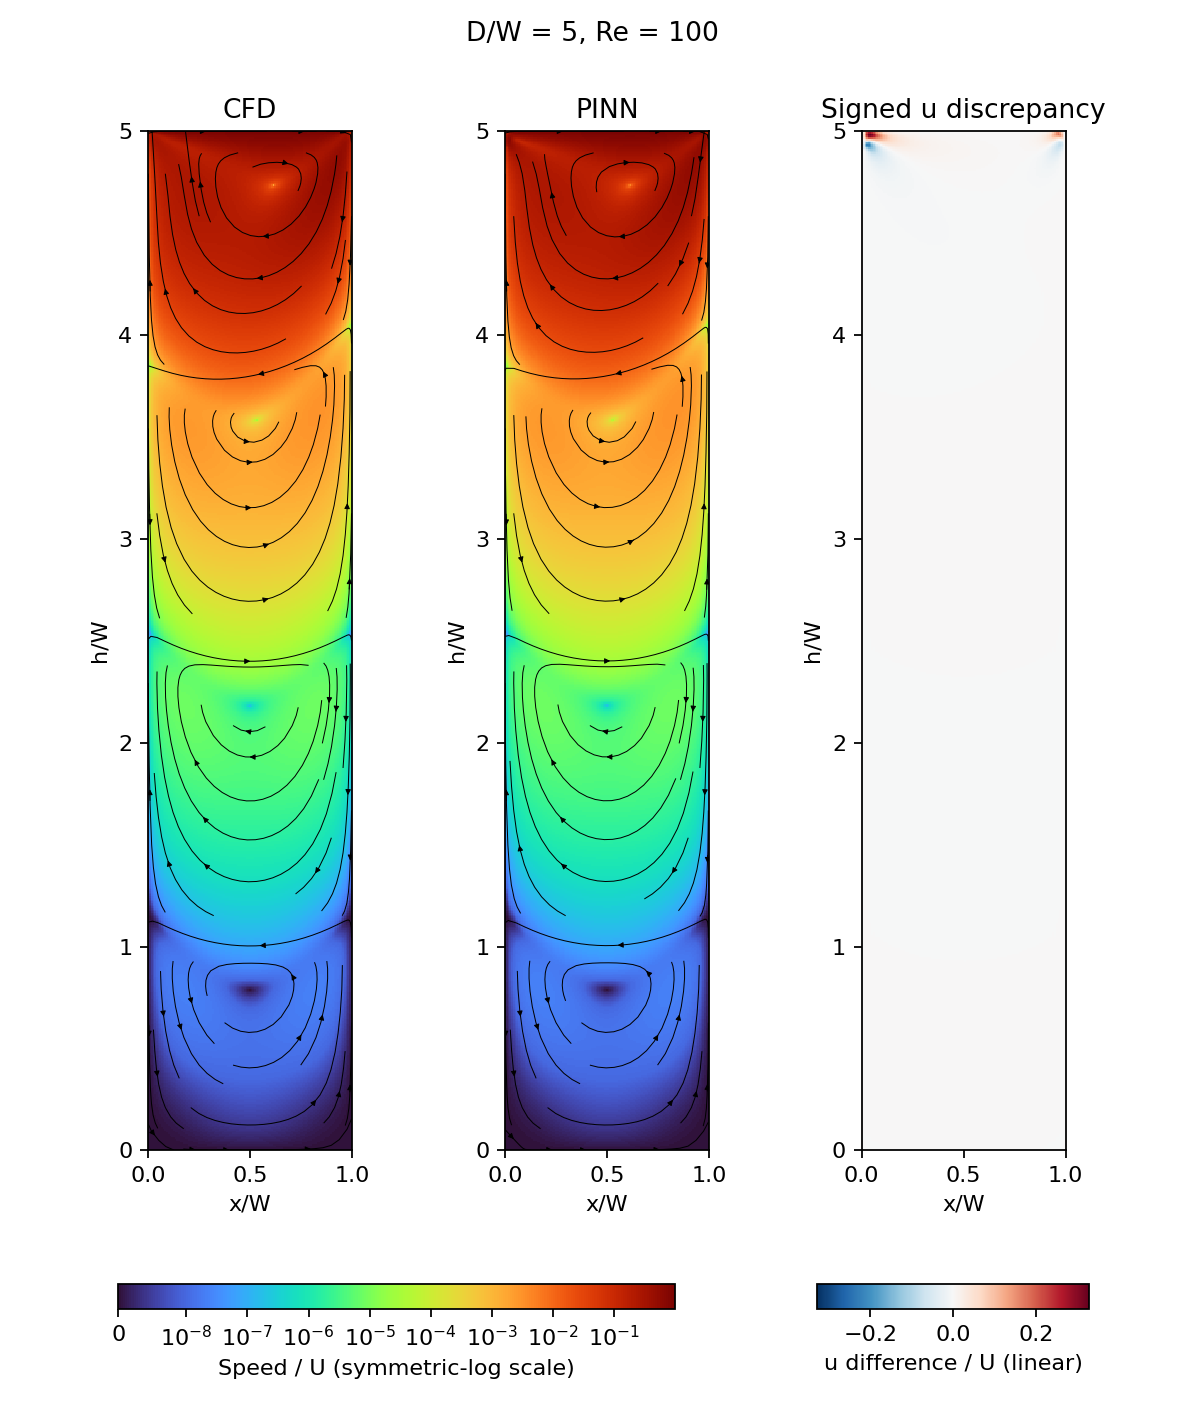

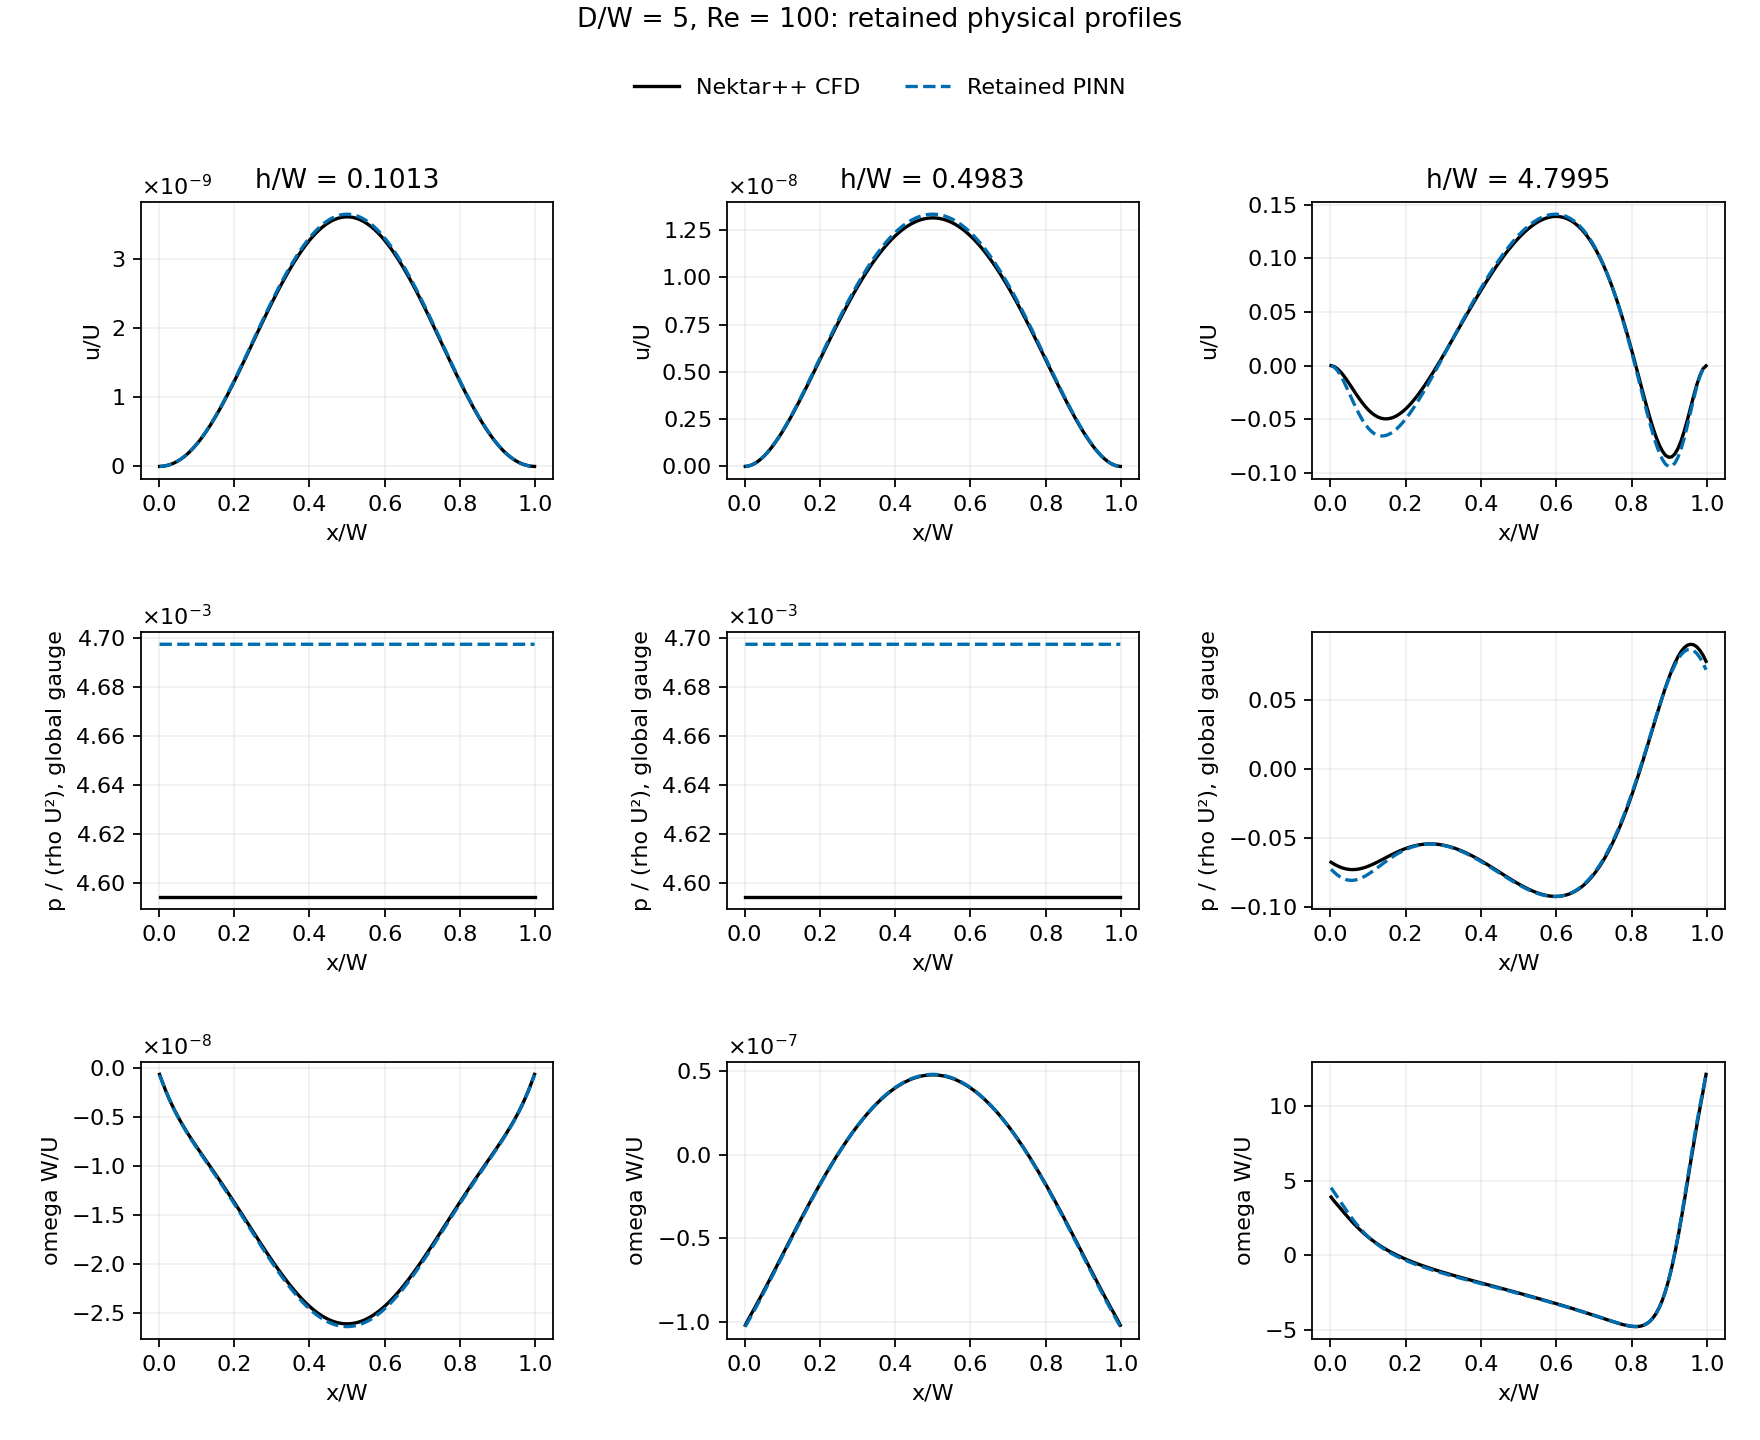

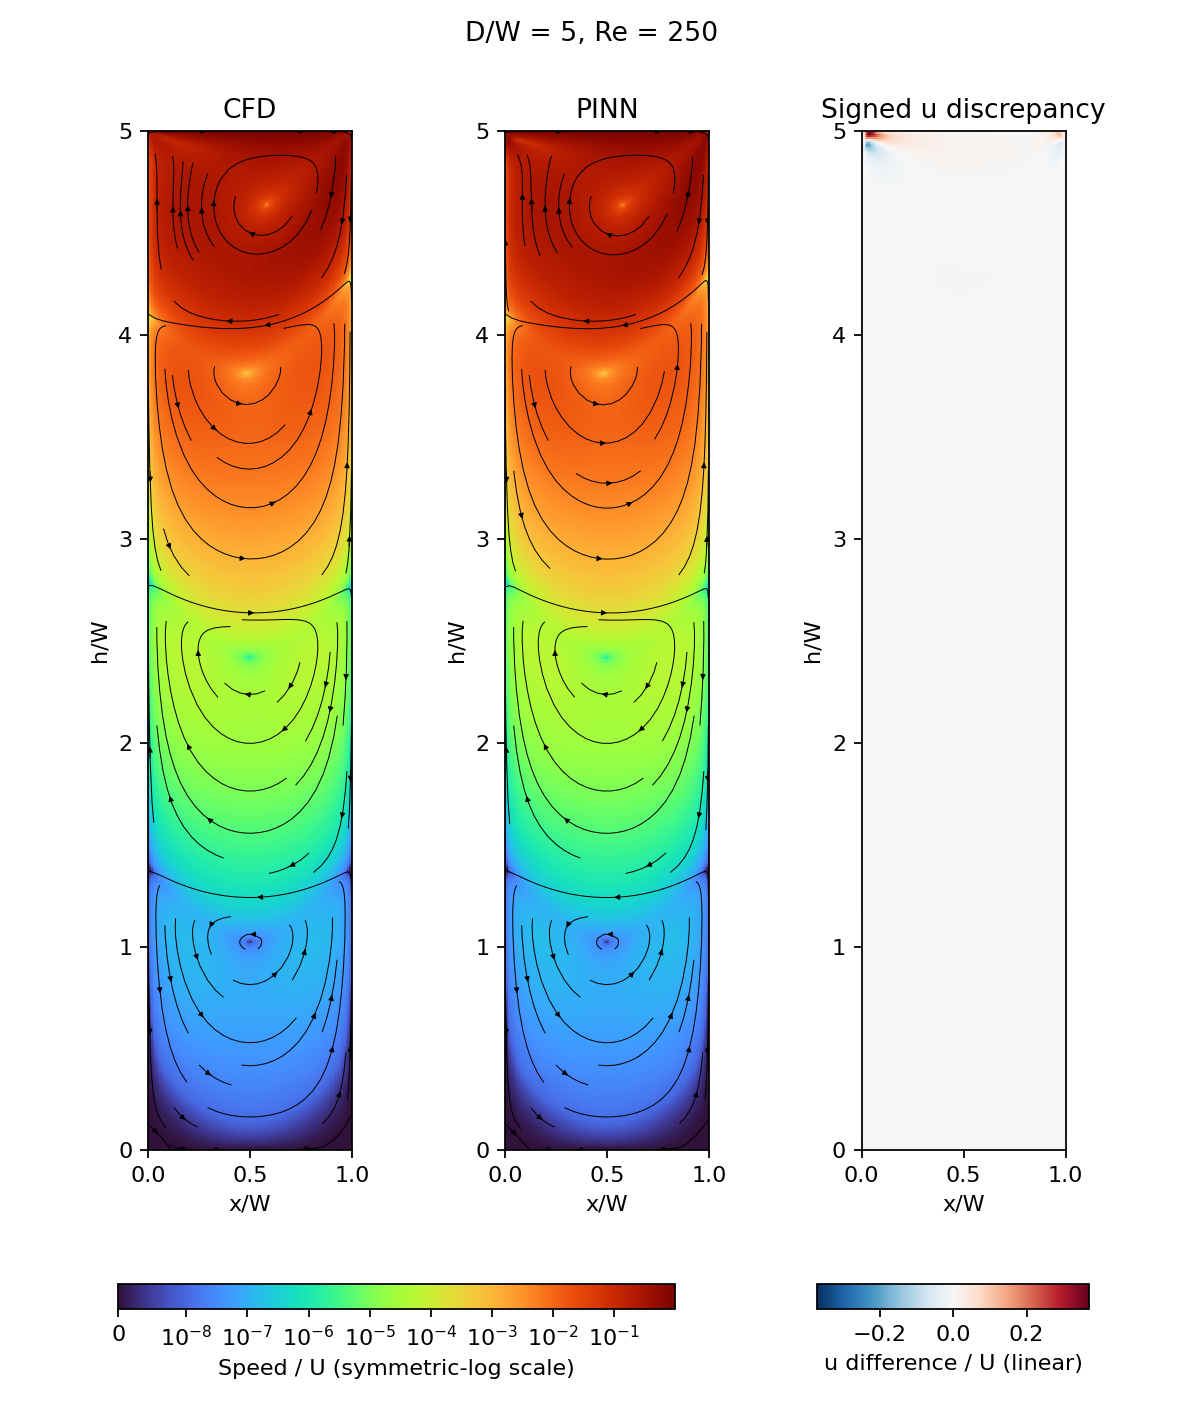

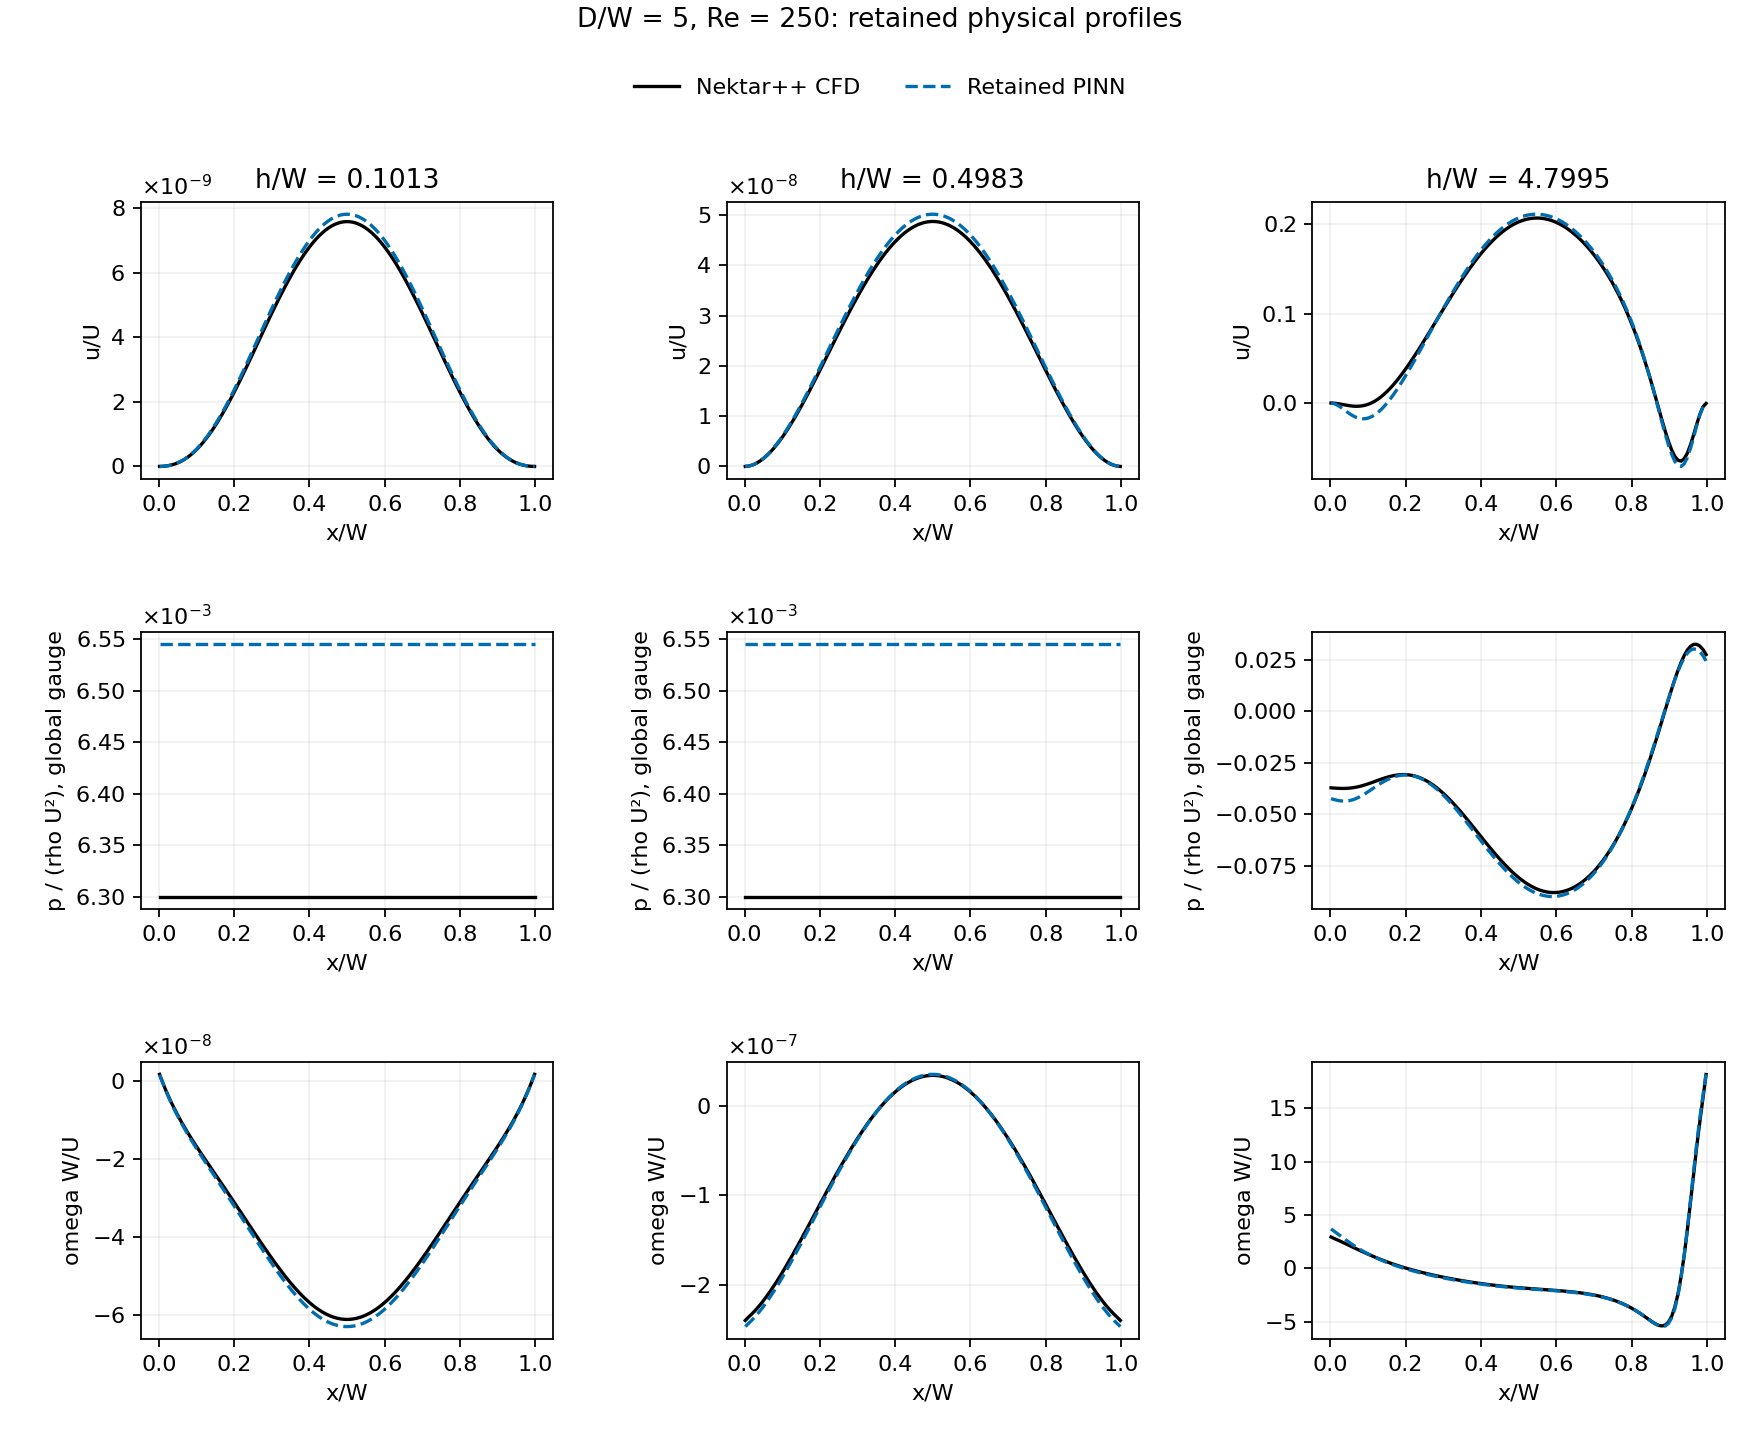

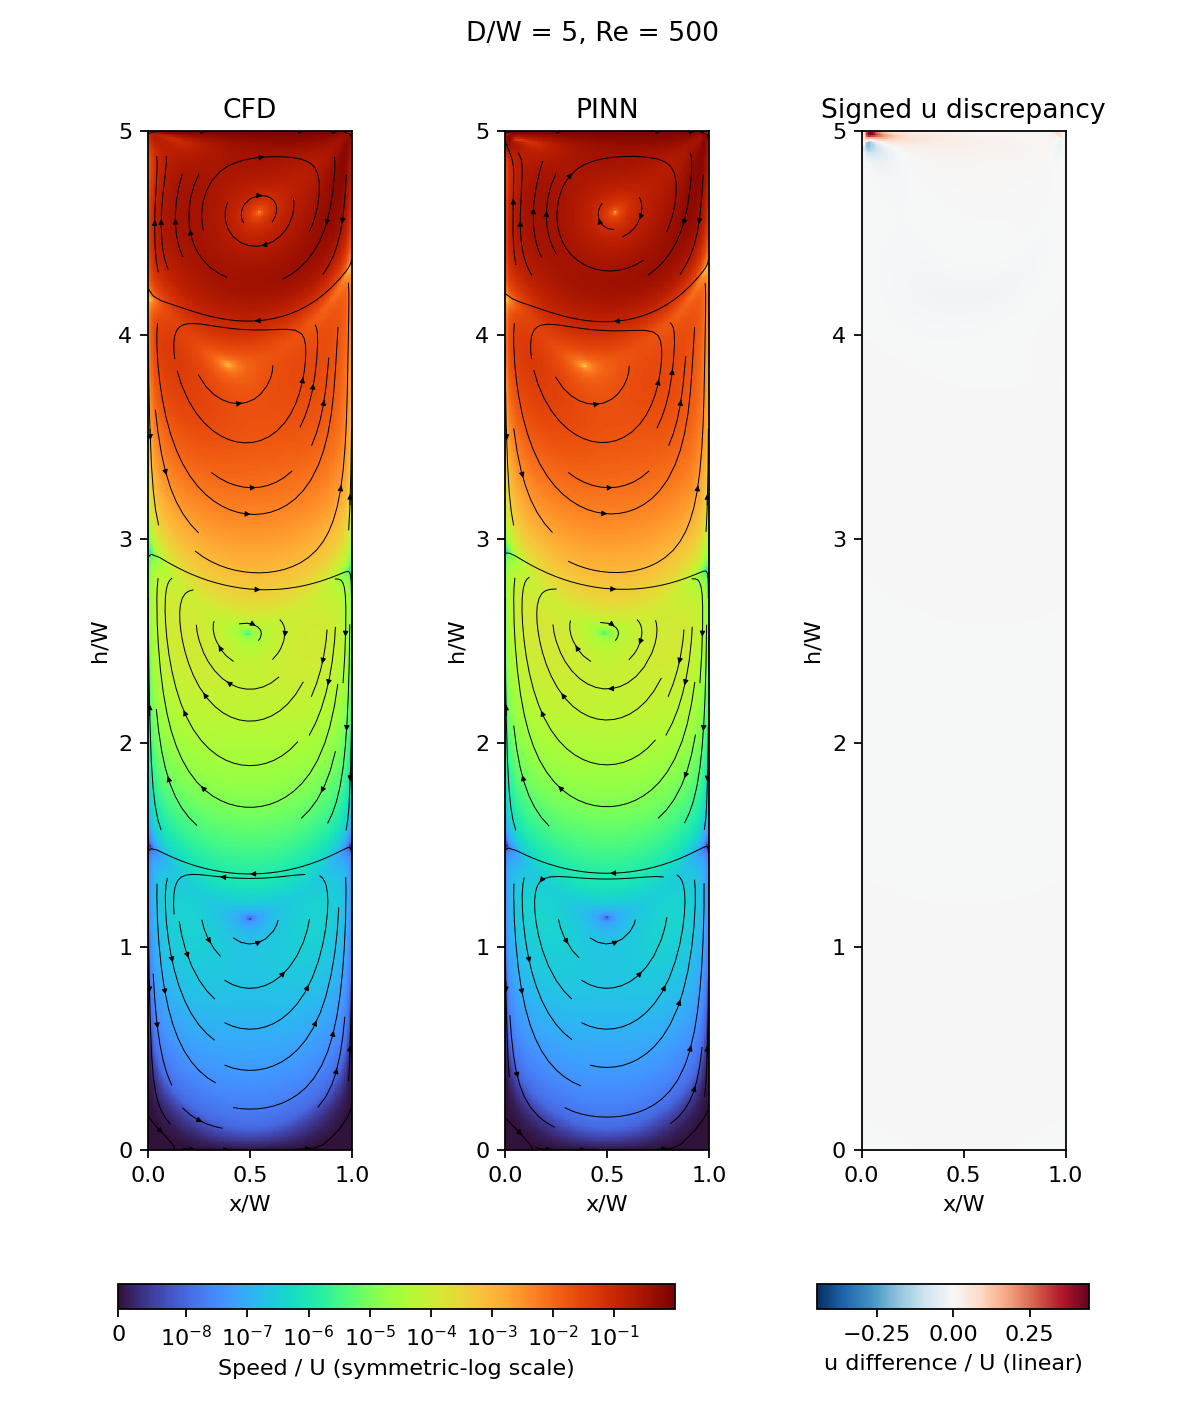

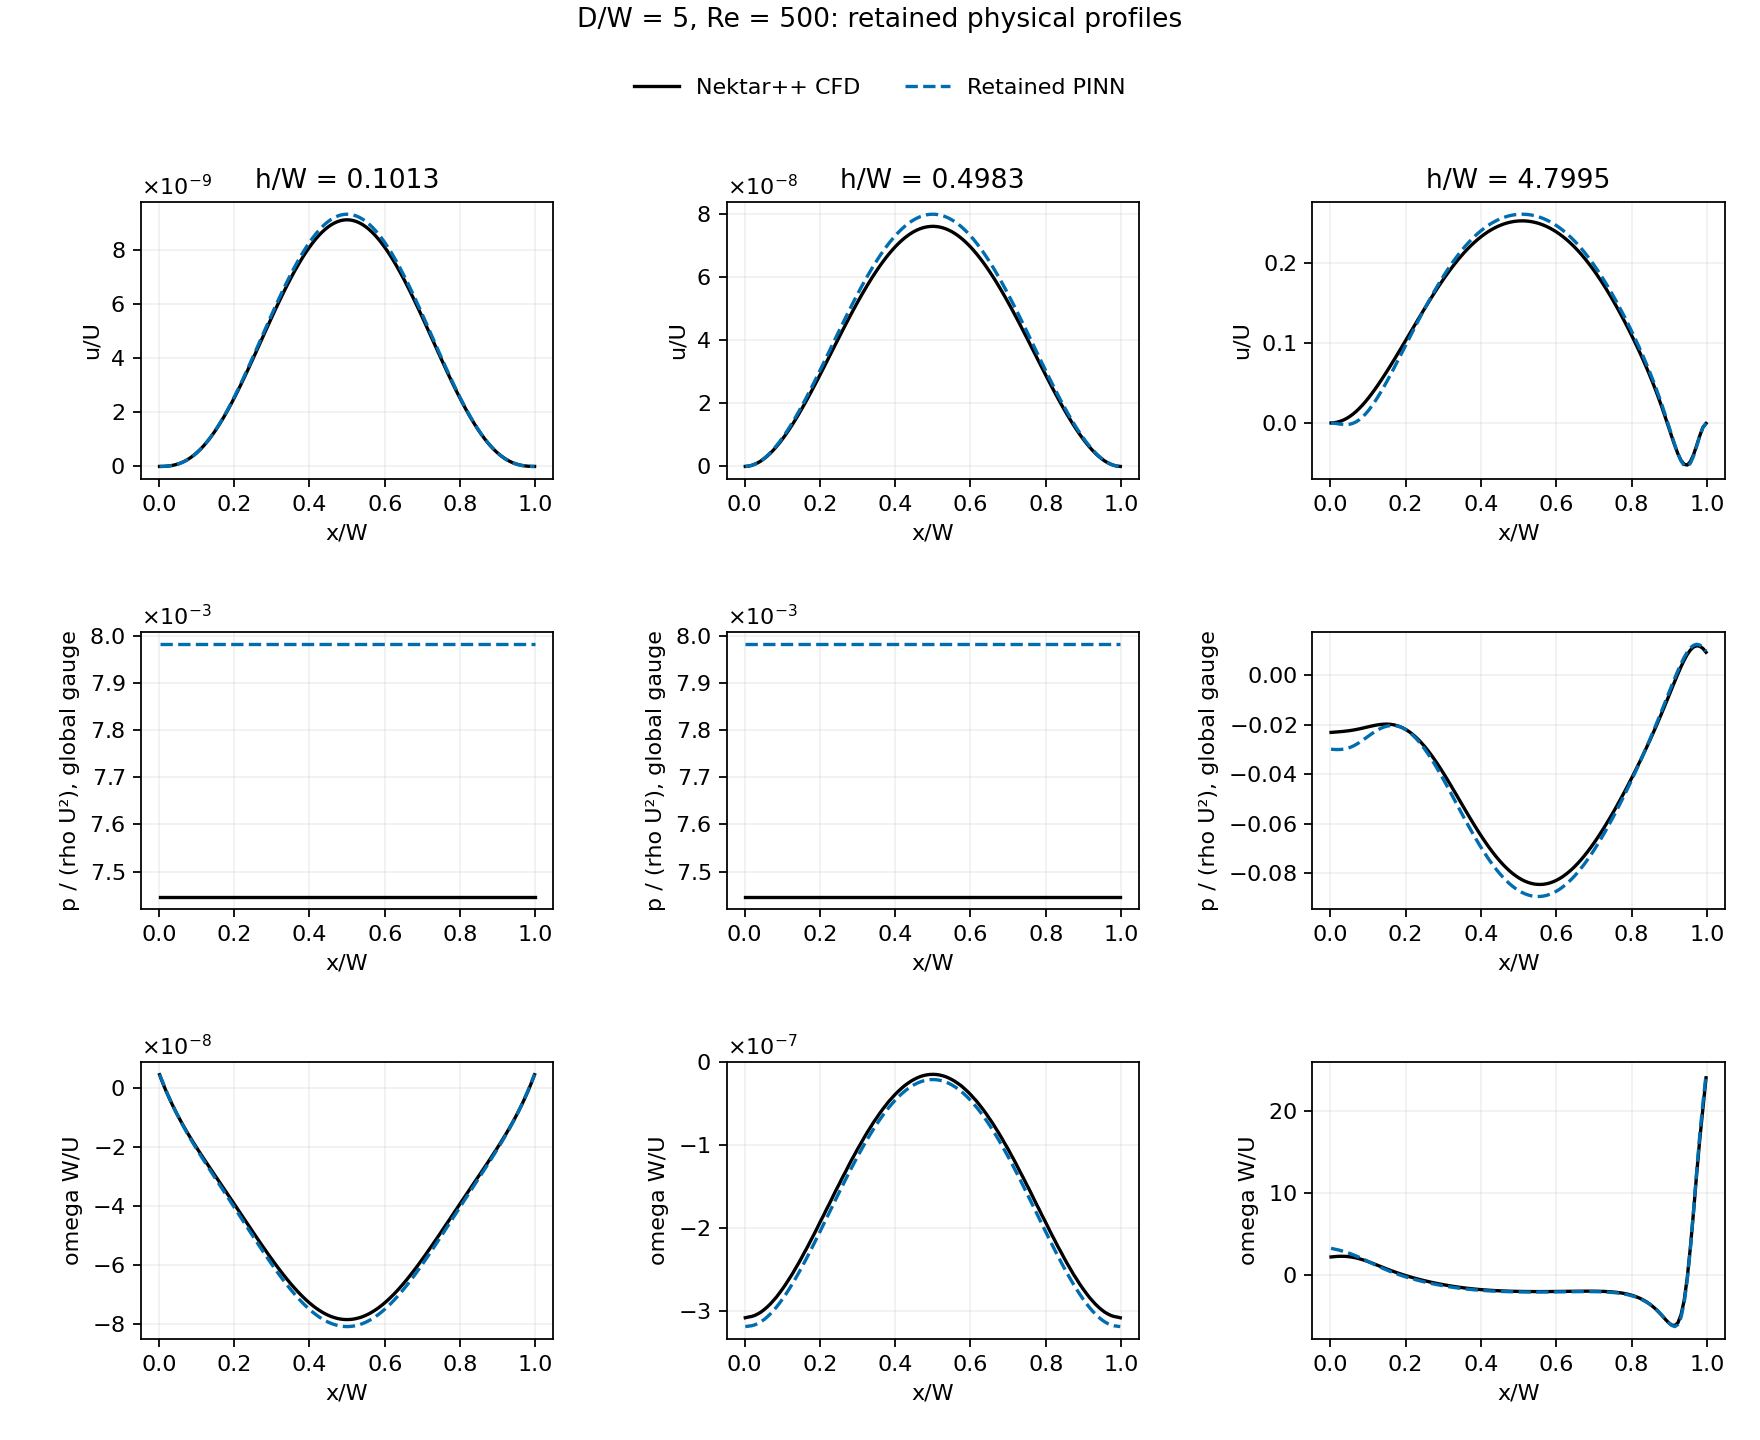

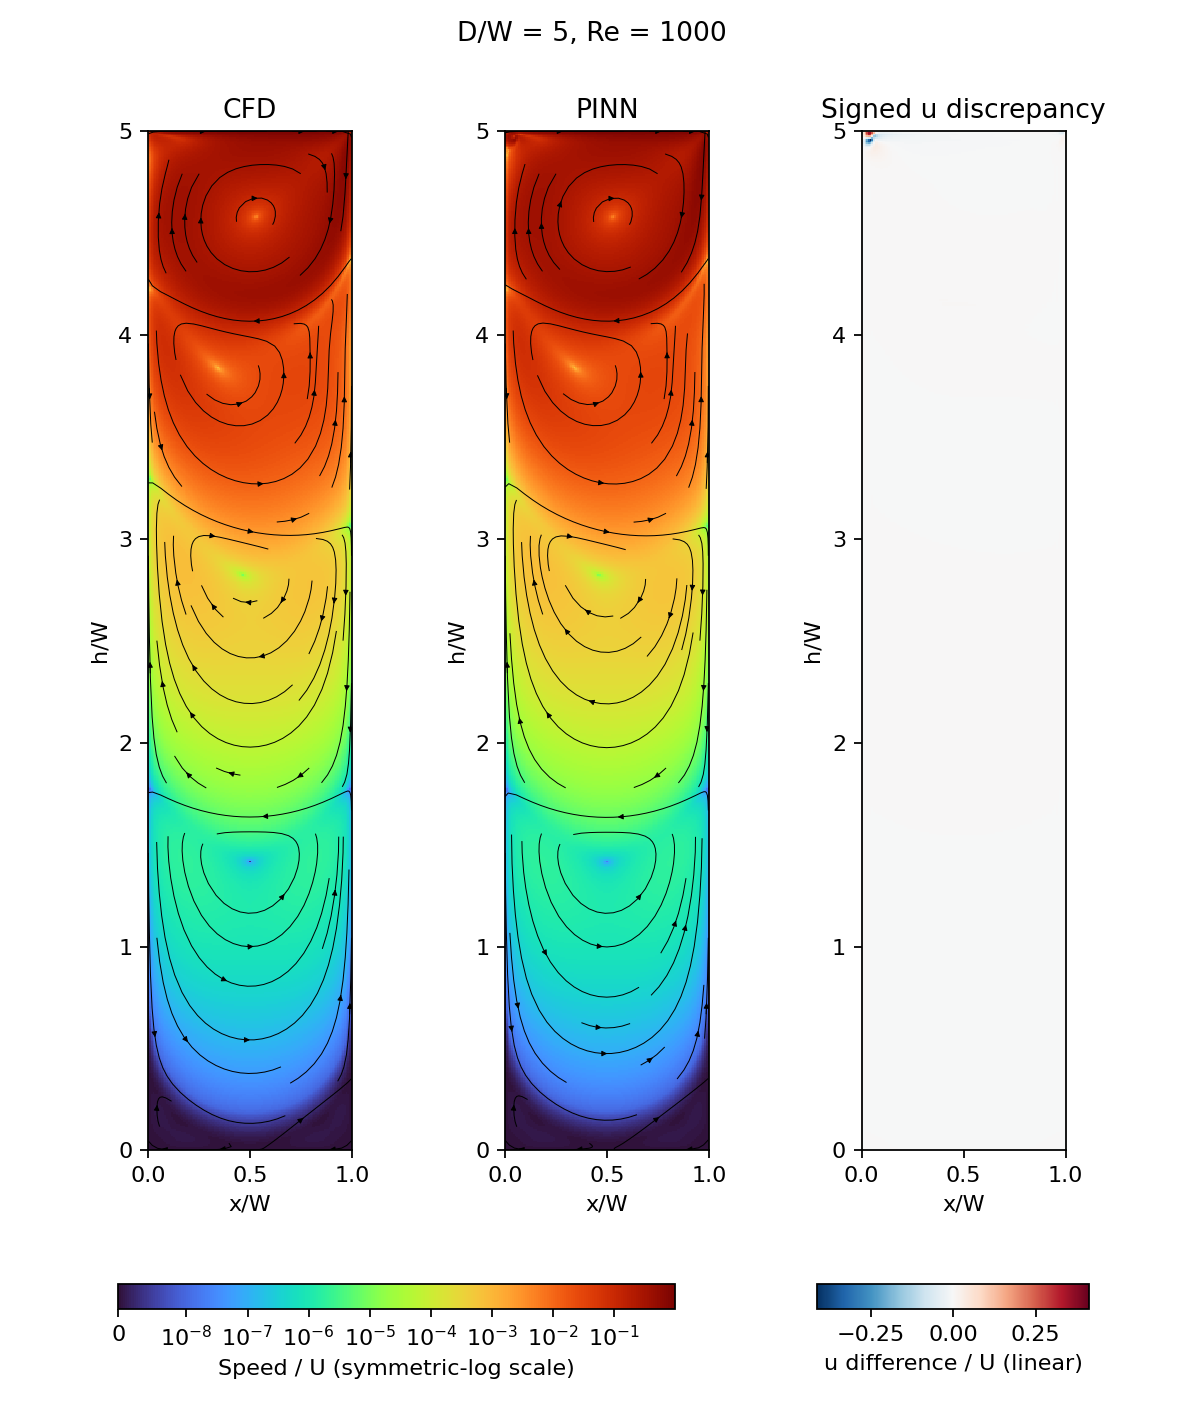

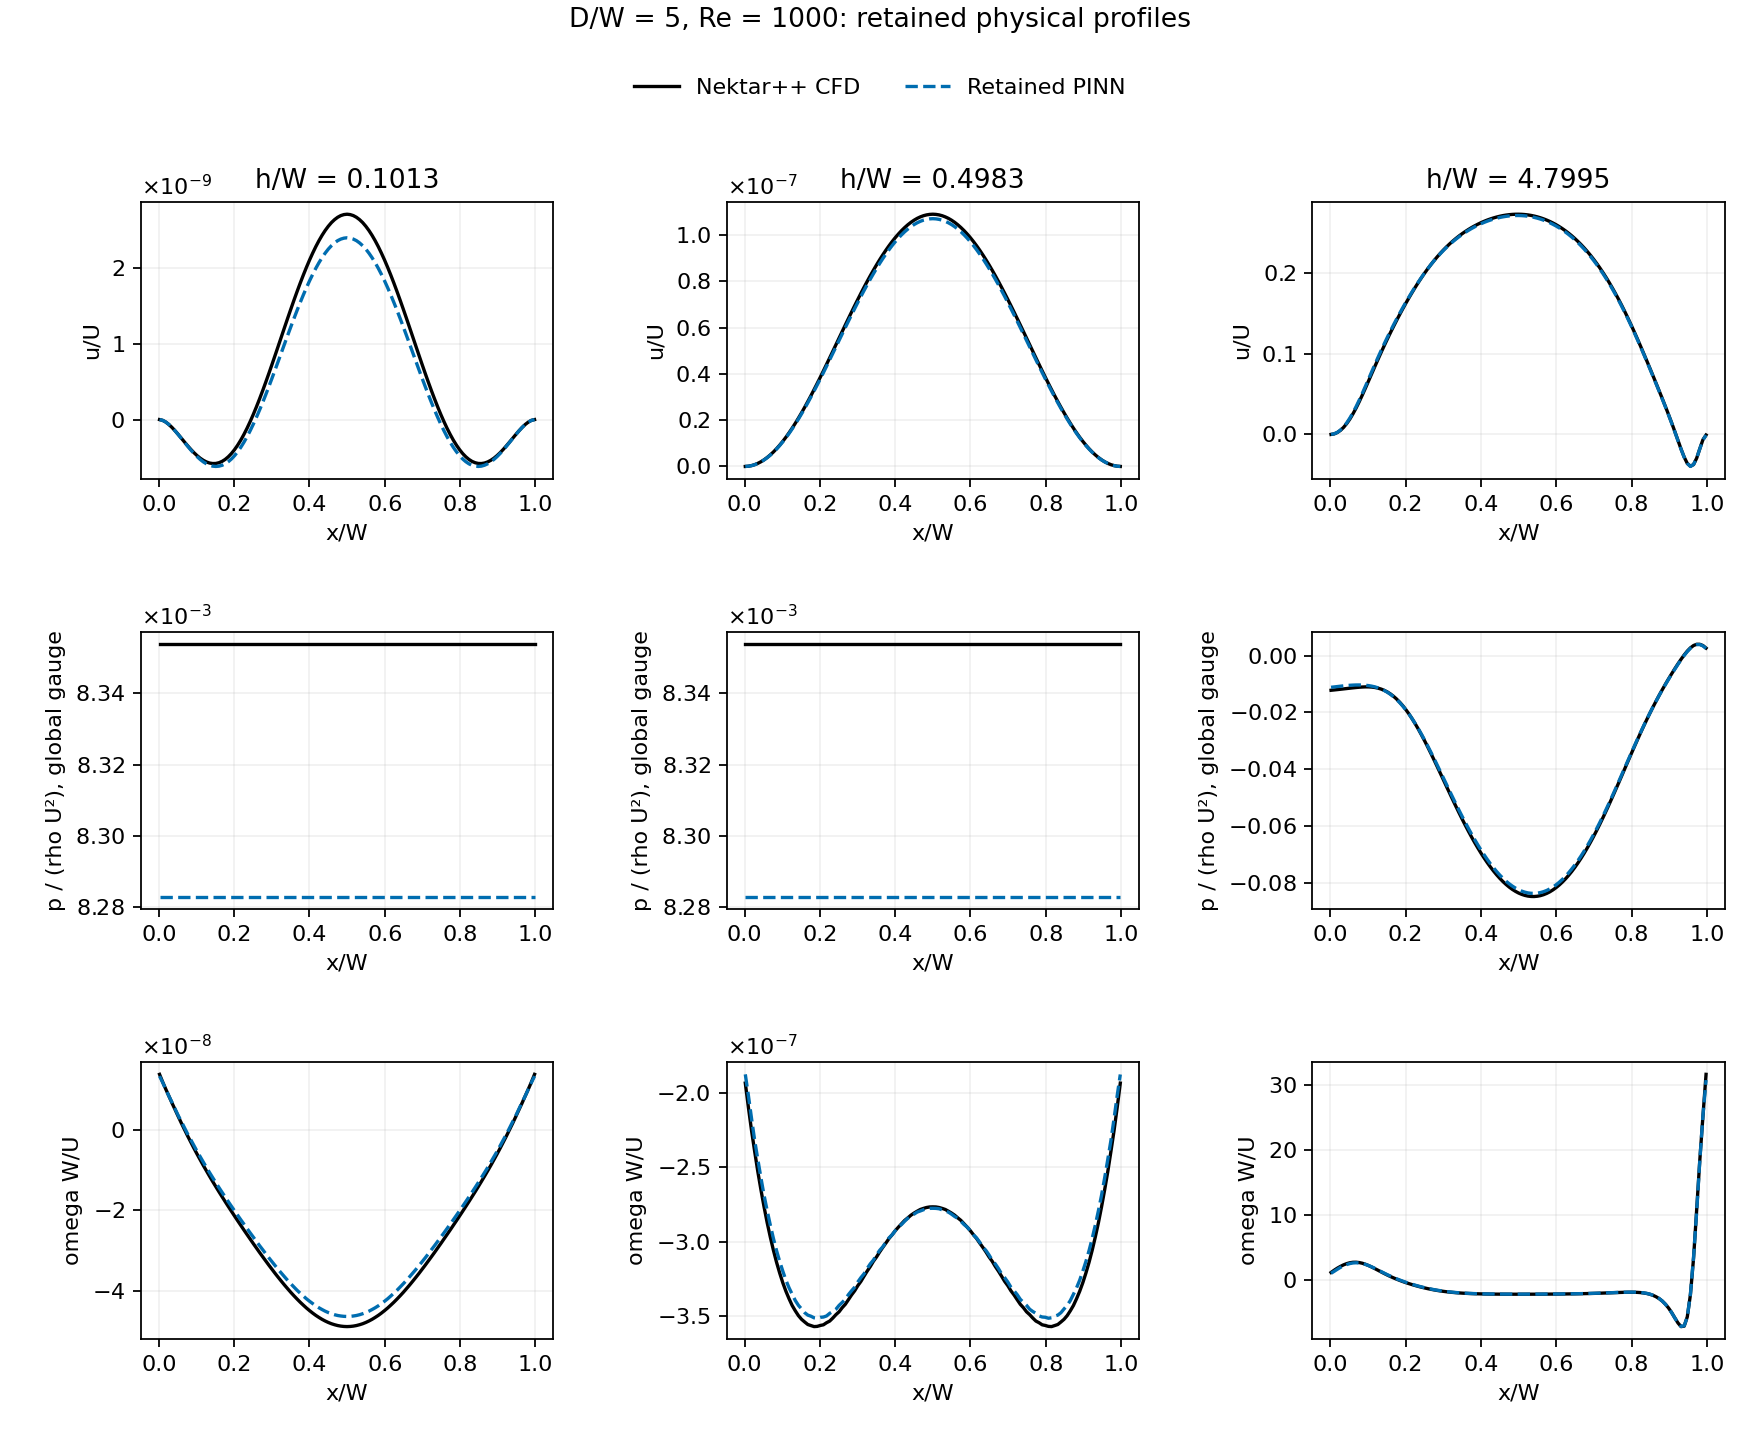

In [4]:
for re in (100,250,500,1000):
    print(f'Re = {re}: matched geometry/lid, common sampled grid')
    display(Image(filename=str(ROOT/f'results/week13_d5/re{re}_fields.png'),width=650))
    display(Image(filename=str(ROOT/f'results/week13_d5/re{re}_profiles.png'),width=900))

## 4. Optimization history: what improved, and what was not isolated

The paper compares accumulated workflows, including transferred initialization,
regional collocation, residual scaling/envelope choices and a SOAP-to-self-scaled
Broyden refinement stage. Equal final refinement steps do not erase unequal prior
training histories. The pressure and vorticity rankings can differ from velocity.
Read the source and provenance before attributing gains to one optimizer.

In the separate 161 by 801 Re=1000 assessment, the control-to-refined interior
velocity discrepancy decreases from 5.624% to 2.658%, and pressure RMS from
0.002793 to 0.001167 rho U squared. This is retained research evidence, not a new
controlled optimizer ablation. The common-grid results above use a different
sampling grid and must not be mixed into the same ranking.

The public [paper ancillary analysis code](https://arxiv.org/abs/2610.38814v2)
and [DeepPlasma cavity implementation](https://github.com/cmcdevitt2/DeepPlasma/tree/fcb1566eaa3253d4a4108fbac9d49a38fd10ad6b/LDC)
provide the original context. FlowMLLab's existing `qa/WEEK13_PINN_MATRIX_PROTOCOL.md`
and runners provide its separate Adam/SSBroyden2 training exercise. This notebook's
portable code is `flowmllab/deep_cavity_audit.py`; it reproduces field assessment,
not the full optimizer/RNG checkpoint history of the paper.

In [5]:
workflow = pd.read_csv(ROOT/'results/week13_d5/workflow_metrics.csv')
display(workflow[workflow.region=='Interior'][['workflow','velocity_NRMSE_percent',
    'pressure_RMS_rhoU2','vorticity_RMS_UoverW']])
print('Frozen author assessment on 161x801; one trajectory per workflow, unequal histories.')

Frozen author assessment on 161x801; one trajectory per workflow, unequal histories.


,workflow,velocity_NRMSE_percent,pressure_RMS_rhoU2,vorticity_RMS_UoverW
0,Control,5.624258,0.002793,0.800949
4,Soft residual,3.961758,0.001195,0.366896
8,Refined,2.658187,0.001167,0.314228
12,Half envelope,3.843625,0.001064,0.358329


## 5. Engineering exercises and required submission

Submit your notebook, the two tables below, four physical-profile figures and a
one-page interpretation. Keep signs, units, sample counts and reference identity.

1. **Table A: weak-flow audit.** For every Re, report Interior and Floor_0.4 sample
   count, absolute vector RMS, reference RMS and relative error. Verify their
   algebraic relation. Explain why $10^{-9}U$ alone does not establish nine-digit accuracy.
2. **Region sensitivity.** Change the floor cutoff from 0.4 to 0.65 W using `masks`
   and compare the rankings without changing the fields. Plot u and v at a
   retained height inside each region. Report the actual height returned by the code.
3. **Pressure gauge.** Add a constant 0.001 to a copy of the predicted pressure.
   Show how global RMS, regional offset and local shape respond. Then restore the
   original arrays; do not modify the supplied NPZ.
4. **Derivative sensitivity.** Recompute vorticity with second-order differences
   and compare with the retained sampled vorticity. Repeat after subsampling the
   common grid by two. This tests postprocessing resolution, not native CFD mesh convergence.
5. **Table B: workflow trade-offs.** From `workflow_metrics.csv`, rank all four
   workflows by velocity, pressure RMS and vorticity separately in Interior,
   Upper-left and Floor_0.4. Identify where a workflow improves one variable and
   loses on another. Do not hide a weak corner behind a full-domain norm.
6. **Design an isolated experiment.** Fix lid, Re, geometry, initialization,
   collocation, precision and audit samples. Compare depth 2/5 at matched parameter
   counts, Adam/L-BFGS/SSBroyden2 with counted evaluations, and uniform/regional
   weights one at a time. Use at least three seeds and an untouched validation
   reference. Freeze collocation and weights during each quasi-Newton stage;
   otherwise the line-search objective changes. No new paper-quality gain is
   claimed until this experiment and the reference checks are actually run.

Actual retained h/W: 0.2997748344370861


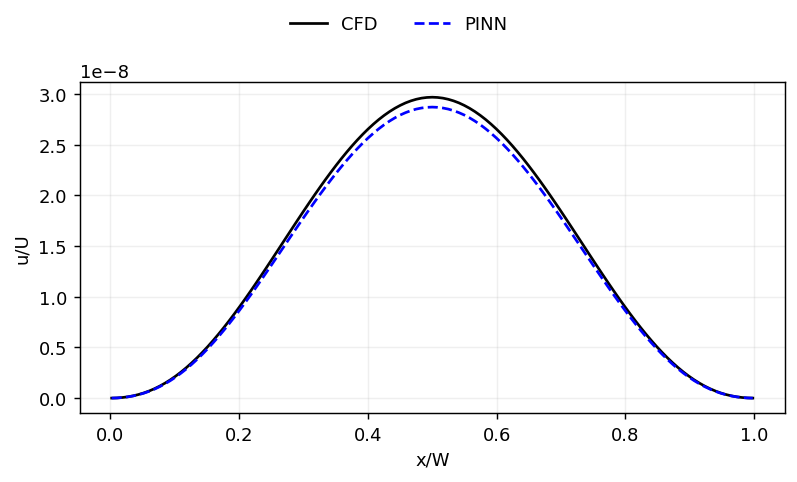

In [6]:
# Student starting point: an actual retained profile, not an interpolated floor point.
RE = 1000
HEIGHT = 0.3
fig,ax=plt.subplots(figsize=(7,3.8))
for method,style in [('cfd','k-'),('pinn','b--')]:
    x,values,actual_h=horizontal_profile(fields,RE,method,'u',HEIGHT)
    ax.plot(x,values,style,label=method.upper())
ax.set(xlabel='x/W',ylabel='u/U');ax.grid(alpha=.2)
fig.legend(*ax.get_legend_handles_labels(),loc='upper center',ncol=2,frameon=False)
fig.subplots_adjust(top=.84,bottom=.17)
print('Actual retained h/W:',actual_h)
plt.show()